In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/Unicorn_Companies_cleaned.csv")
print("Shape:", df.shape)

num_cols = ["Valuation", "Total Raised (M)", "Investors Count", "Deal Terms", "Years to Unicorn"]
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurtosis()
desc.round(2)

In [2]:
# Log-transform skewed variables
df["log_val"] = np.log(df["Valuation"])
df["log_raised"] = np.log(df["Total Raised (M)"])

# 95% confidence interval for mean log-valuation, converted back to $B
x = df["log_val"].dropna()
ci = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
print("95%% CI for geometric-mean valuation: $%.2fB to $%.2fB" % tuple(np.exp(ci)))

# 95% CI by top industries
print("\nGeometric-mean valuation by industry (top 5):")
for ind in df["Industry"].value_counts().head(5).index:
    s = df.loc[df["Industry"] == ind, "log_val"]
    lo, hi = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
    print(f"  {ind}: ${np.exp(s.mean()):.2f}B  (CI ${np.exp(lo):.2f}B to ${np.exp(hi):.2f}B)")

# Welch t-test: US vs non-US (on log valuation)
us = df.loc[df["Country"] == "United States", "log_val"]
non_us = df.loc[df["Country"] != "United States", "log_val"]
t, p = stats.ttest_ind(us, non_us, equal_var=False)
pooled_sd = np.sqrt((us.var() + non_us.var()) / 2)
d = (us.mean() - non_us.mean()) / pooled_sd
print(f"\nUS vs non-US: t={t:.2f}, p={p:.4f}, Cohen's d={d:.2f}")
print(f"Geometric means: US ${np.exp(us.mean()):.2f}B vs non-US ${np.exp(non_us.mean()):.2f}B")

95% CI for geometric-mean valuation: $1.96B to $2.15B

Geometric-mean valuation by industry (top 5):
  Fintech: $2.24B  (CI $2.00B to $2.51B)
  Internet software & services: $2.07B  (CI $1.87B to $2.28B)
  E-commerce & direct-to-consumer: $2.04B  (CI $1.77B to $2.35B)
  Artificial intelligence: $1.90B  (CI $1.59B to $2.27B)
  Health: $1.97B  (CI $1.66B to $2.33B)

US vs non-US: t=2.18, p=0.0297, Cohen's d=0.14
Geometric means: US $2.16B vs non-US $1.95B


In [3]:
# ANOVA: log valuation across industries
groups = [g["log_val"].dropna() for _, g in df.groupby("Industry")]
F, p = stats.f_oneway(*groups)
k, n = len(groups), sum(len(g) for g in groups)
grand = np.concatenate(groups).mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = sum(((g - grand) ** 2).sum() for g in groups)
print(f"ANOVA (industry): F={F:.2f}, p={p:.4f}, eta-squared={ss_between / ss_total:.3f}")

# Tukey HSD post-hoc (only meaningful if ANOVA is significant)
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tuk = pairwise_tukeyhsd(df["log_val"].dropna(), df.loc[df["log_val"].notna(), "Industry"])
res = pd.DataFrame(tuk._results_table.data[1:], columns=tuk._results_table.data[0])
print("\nSignificant Tukey pairs:", (res["reject"] == True).sum(), "of", len(res))
print(res[res["reject"] == True])

# Chi-square: industry vs Exited
ct = pd.crosstab(df["Industry"], df["Exited"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"\nChi-square (industry vs exited): chi2={chi2:.2f}, dof={dof}, p={p:.4f}, Cramer's V={cramers_v:.3f}")
print("Cells with expected count < 5:", (exp < 5).sum(), "of", exp.size)

ANOVA (industry): F=0.68, p=0.7937, eta-squared=0.009

Significant Tukey pairs: 0 of 105
Empty DataFrame
Columns: [group1, group2, meandiff, p-adj, lower, upper, reject]
Index: []

Chi-square (industry vs exited): chi2=27.48, dof=14, p=0.0167, Cramer's V=0.163
Cells with expected count < 5: 12 of 30


In [ ]:
# Exit rate by industry
rate = df.groupby("Industry")["Exited"].agg(["sum", "count", "mean"])
rate.columns = ["exited", "total", "exit_rate"]
print(rate.sort_values("exit_rate", ascending=False).round(3))

# Permutation test: shuffle Exited labels, recompute chi-square
rng = np.random.default_rng(42)
obs = chi2
labels = df["Exited"].values.copy()
count = 0
n_perm = 5000
for _ in range(n_perm):
    rng.shuffle(labels)
    c, _, _, _ = stats.chi2_contingency(pd.crosstab(df["Industry"], labels))
    count += c >= obs
print(f"\nPermutation p-value (5000 shuffles): {(count + 1) / (n_perm + 1):.4f}")

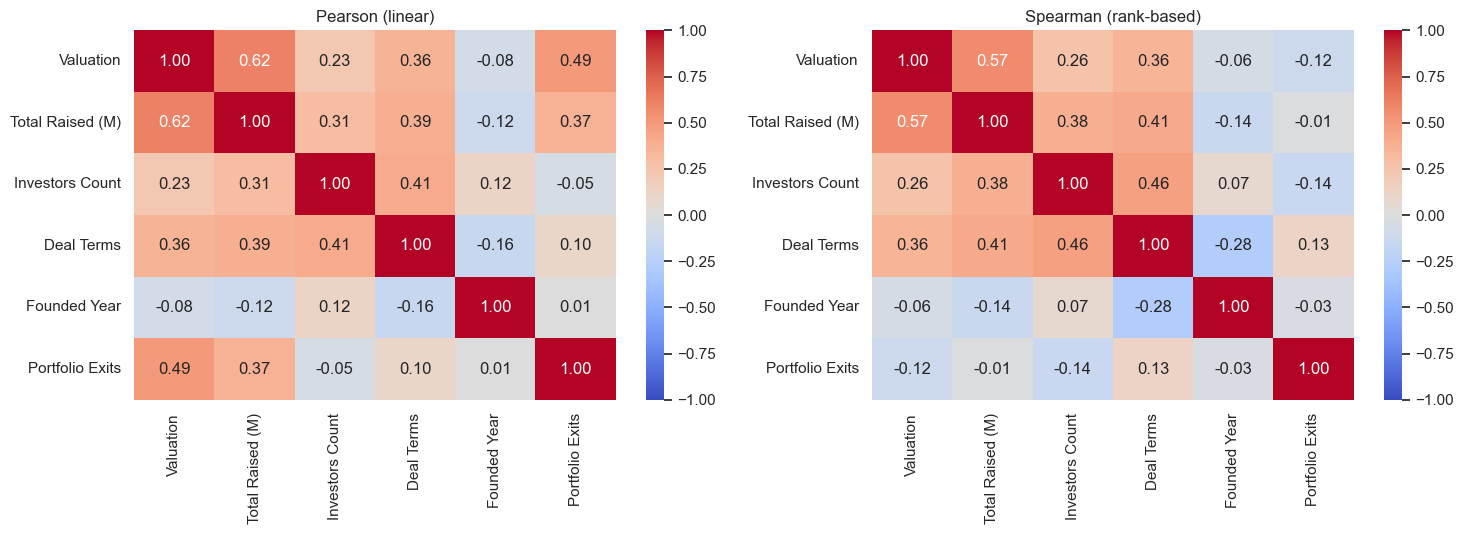

                  Pearson  Spearman
Valuation            1.00      1.00
Total Raised (M)     0.62      0.57
Investors Count      0.23      0.26
Deal Terms           0.36      0.36
Founded Year        -0.08     -0.06
Portfolio Exits      0.49     -0.12


In [5]:
import os
os.makedirs("../results/plots", exist_ok=True)

cols = ["Valuation", "Total Raised (M)", "Investors Count", "Deal Terms", "Founded Year", "Portfolio Exits"]
pearson = df[cols].corr(method="pearson")
spearman = df[cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson (linear)")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman (rank-based)")
plt.tight_layout()
plt.savefig("../results/plots/02_correlations.png", dpi=150)
plt.show()

# Valuation correlations side by side
print(pd.DataFrame({"Pearson": pearson["Valuation"], "Spearman": spearman["Valuation"]}).round(2))

In [6]:
print("KEY FINDINGS (Notebook 2)")
print("- Typical valuation (geometric mean): $1.96B-$2.15B; Valuation skew = %.1f" % df["Valuation"].skew())
print("- US vs non-US: p=0.03 but Cohen's d=0.14 (tiny effect)")
print("- Industry does not explain valuation: ANOVA p=0.79, eta^2=0.009")
print("- Exit rate differs by industry: permutation p=0.023, Cramer's V=0.16")
print("- Strongest valuation correlate: Total Raised (Spearman 0.57)")
print("- Portfolio Exits correlation is an artifact (n=49): Pearson 0.49 vs Spearman -0.12")

KEY FINDINGS (Notebook 2)
- Typical valuation (geometric mean): $1.96B-$2.15B; Valuation skew = 11.6
- US vs non-US: p=0.03 but Cohen's d=0.14 (tiny effect)
- Industry does not explain valuation: ANOVA p=0.79, eta^2=0.009
- Exit rate differs by industry: permutation p=0.023, Cramer's V=0.16
- Strongest valuation correlate: Total Raised (Spearman 0.57)
- Portfolio Exits correlation is an artifact (n=49): Pearson 0.49 vs Spearman -0.12
